# Transfer Learning with VGG16: Skin Lesion Classification

In the previous session, we trained small CNNs from scratch on MNIST. Here, the task is harder: classifying dermatoscopic images of skin lesions as **cancer** or **benign**, with only about 7,000 training images.

Training a large CNN from scratch on so few images leads to overfitting. **Transfer learning** solves this by reusing a network already trained on a huge dataset (here VGG16, trained on the 1.2 million images of ImageNet) and adapting it to our task.

**Steps**
1. Load and explore the data (DermaMNIST, RGB 224 x 224)
2. Train a small CNN from scratch as a baseline
3. Try VGG16 as it is, on our images
4. Transfer learning, step 1: feature extraction (frozen VGG16 + new classifier)
5. A paradox: adding a layer that reduces the number of parameters
6. Transfer learning, step 2: fine-tuning
7. Final evaluation on the test set

## 0. Setup: use a GPU

VGG16 on 224 x 224 images needs a GPU. As in the previous session, use one of the following:
- **A local NVIDIA GPU**, with a GPU-enabled TensorFlow installation (Linux, or WSL2 on Windows).
- **Google Colab**: open this notebook on [colab.research.google.com](https://colab.research.google.com), then select *Runtime > Change runtime type > T4 GPU*.
- **Colab from VS Code**: follow [this guide](https://medium.com/@chongcht/google-colab-comes-to-vs-code-complete-setup-guide-a55a2fdc296c).

Run the cell below and check that it prints `GPU available: True`.

If you run out of GPU memory, reduce `BATCH_SIZE` to 16. If training is too slow, set `IMAGE_SIZE = 128` (the dataset also exists at this resolution, and VGG16 accepts it).

In [1]:
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers

print(f"Platform: {platform.platform()}")
print(f"Python {sys.version.split()[0]}")
print(f"TensorFlow {tf.__version__}, Keras {keras.__version__}")

gpus = tf.config.list_physical_devices("GPU")
print("GPU available:", len(gpus) > 0)
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

keras.utils.set_random_seed(42)

IMAGE_SIZE = 224   # 224 (default) or 128
BATCH_SIZE = 32

Platform: Linux-6.6.122+-x86_64-with-glibc2.39
Python 3.13.15
TensorFlow 2.21.0, Keras 3.13.2
GPU available: True


## 1. Load and explore the data

We use **DermaMNIST**, from the [MedMNIST](https://medmnist.com) collection. It is built from HAM10000, a set of 10,015 dermatoscopic images of skin lesions in 7 categories, and comes already split into training (7,007), validation (1,003) and test (2,005) sets.

The cell below downloads the file (a large download, done once and then cached) and loads the six arrays. The images are RGB, with integer pixel values from 0 to 255 (`uint8`). We keep them in this format to save memory: the models will convert them to floats themselves.

In [2]:
DATA_FILES = {
    224: ("dermamnist_224.npz", "8974907d8e169bef5f5b96bc506ae45d"),
    128: ("dermamnist_128.npz", "2defd784463fa5243564e855ed717de1"),
}
fname, md5 = DATA_FILES[IMAGE_SIZE]
path = keras.utils.get_file(
    fname, f"https://zenodo.org/records/10519652/files/{fname}?download=1", file_hash=md5
)

data = np.load(path)
X_train, y_train_7 = data["train_images"], data["train_labels"].ravel()
X_valid, y_valid_7 = data["val_images"], data["val_labels"].ravel()
X_test, y_test_7 = data["test_images"], data["test_labels"].ravel()

print(X_train.shape, X_train.dtype, y_train_7.shape)
print(X_valid.shape, X_test.shape)

1091112502/1091112502 ━━━━━━━━━━━━━━━━━━━━ 386s 0us/step
(7007, 224, 224, 3) uint8 (7007,)
(1003, 224, 224, 3) (2005, 224, 224, 3)


### From 7 diseases to a binary task

The labels are integers from 0 to 6:

| Label | Lesion | Type |
|---|---|---|
| 0 | Actinic keratoses and intraepithelial carcinoma | cancer (or pre-cancerous) |
| 1 | Basal cell carcinoma | cancer |
| 2 | Benign keratosis-like lesions | benign |
| 3 | Dermatofibroma | benign |
| 4 | Melanoma | cancer |
| 5 | Melanocytic nevi (moles) | benign |
| 6 | Vascular lesions | benign |

Create binary labels `y_train`, `y_valid` and `y_test`: 1 for cancer (labels 0, 1 and 4), 0 for benign. Use `np.isin`.

In [3]:
CANCER_LABELS = [0, 1, 4]
class_names = ["benign", "cancer"]

# TODO Binary labels: 1 for cancer, 0 for benign
y_train = np.isin(y_train_7, CANCER_LABELS).astype("int32")
y_valid = np.isin(y_valid_7, CANCER_LABELS).astype("int32")
y_test = np.isin(y_test_7, CANCER_LABELS).astype("int32")
print(y_train.shape, y_valid.shape, y_test.shape)

(7007,) (1003,) (2005,)


Display 9 training images with their binary class as title.

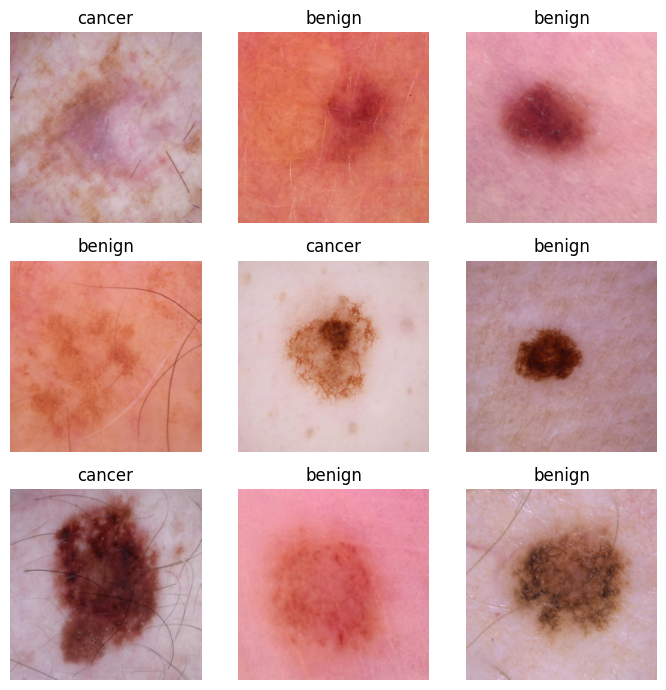

In [4]:
# TODO Display 9 training images with their class
fig, axes = plt.subplots(3, 3, figsize=(7, 7))
for ax, img, label in zip(axes.flat, X_train[:9], y_train[:9]):
    ax.imshow(img)
    ax.set_title(class_names[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

### Class imbalance

Compute the proportion of each class in the training set. Then answer: what accuracy would a "model" get on the validation set by always predicting *benign*?

In [5]:
# TODO Proportion of cancer images in each set
for name, y in [("train", y_train), ("validation", y_valid), ("test", y_test)]:
    print(f"{name}: {y.mean():.3f} cancer, {1 - y.mean():.3f} benign")

# TODO Accuracy of a model always predicting 'benign' on the validation set
always_benign = np.zeros_like(y_valid)
print(f"Always 'benign' - validation accuracy: {(always_benign == y_valid).mean():.3f}")

train: 0.195 cancer, 0.805 benign
validation: 0.195 cancer, 0.805 benign
test: 0.196 cancer, 0.804 benign
Always 'benign' - validation accuracy: 0.805


*Your answer here:*
a model that always predicts *benign* gets an accuracy equal to the proportion of benign images in the validation set

Since accuracy can be misleading here, we will use instead:
- **recall** on the cancer class (sensitivity): the share of cancers that are detected. Missing a cancer is the most serious error;
- **specificity**: the share of benign lesions correctly classified as benign;
- **balanced accuracy**: the mean of recall and specificity;
- **ROC AUC**: measures how well the predicted probabilities rank cancers above benign lesions, independently of the 0.5 threshold (0.5 = random, 1 = perfect).

To make the model pay more attention to the rare class during training, we also use **class weights**: errors on cancer images will count more in the loss.

Compute the class weights with `sklearn.utils.class_weight.compute_class_weight` (option `"balanced"`) and store them in a dictionary `{0: weight_benign, 1: weight_cancer}`, the format expected by `model.fit`.

In [6]:
from sklearn.utils.class_weight import compute_class_weight

# TODO Class weights as a dictionary {0: ..., 1: ...}
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: float(weights[0]), 1: float(weights[1])}
print(class_weight)

{0: 0.621077823081014, 1: 2.564787701317716}


### Helper functions

The functions below are provided:
- `plot_history` plots the loss and ROC AUC curves;
- `evaluate` computes the metrics above on a dataset, displays the confusion matrix and stores the results in the `results` dictionary, so that we can compare models at the end.

In [7]:
from sklearn.metrics import (balanced_accuracy_score, recall_score, roc_auc_score,
                             ConfusionMatrixDisplay)

results = {}

def plot_history(history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(history.history["loss"], label="train")
    ax1.plot(history.history["val_loss"], label="validation")
    ax1.set_title("Loss")
    ax2.plot(history.history["auc"], label="train")
    ax2.plot(history.history["val_auc"], label="validation")
    ax2.set_title("ROC AUC")
    for ax in (ax1, ax2):
        ax.set_xlabel("Epoch")
        ax.legend()
    plt.show()

def evaluate(model, x, y, name):
    probs = model.predict(x, batch_size=BATCH_SIZE, verbose=0).ravel()
    pred = (probs >= 0.5).astype(int)
    scores = {
        "balanced accuracy": balanced_accuracy_score(y, pred),
        "recall (cancer)": recall_score(y, pred),
        "specificity": recall_score(y, pred, pos_label=0),
        "ROC AUC": roc_auc_score(y, probs),
    }
    results[name] = scores
    print(name)
    for metric, value in scores.items():
        print(f"  {metric}: {value:.3f}")
    ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=class_names, colorbar=False)
    plt.show()
    return scores

METRICS = ["accuracy", keras.metrics.AUC(name="auc"), keras.metrics.Recall(name="recall")]

def early_stopping():
    return keras.callbacks.EarlyStopping(
        monitor="val_auc", mode="max", patience=4, restore_best_weights=True
    )

### Data augmentation

With few training images, we can artificially create variety by applying random transformations to the images at each epoch. A skin lesion has no natural orientation, so flips and rotations do not change its class.

In Keras 3, data augmentation is done with `Random*` layers placed at the start of the model (the old `ImageDataGenerator` is deprecated). These layers are only active during training: at prediction time, images go through unchanged. Each epoch sees a different random version of each image, so the number of training images does not need to be increased.

Create a `data_augmentation` model (`keras.Sequential`) with:
- `RandomFlip("horizontal_and_vertical")`;
- `RandomRotation(0.25)` (up to a quarter turn);
- `RandomZoom(0.1)`.

La data augmentation (augmentation de données), c'est créer artificiellement de la variété dans tes images d'entraînement en leur appliquant des transformations aléatoires.

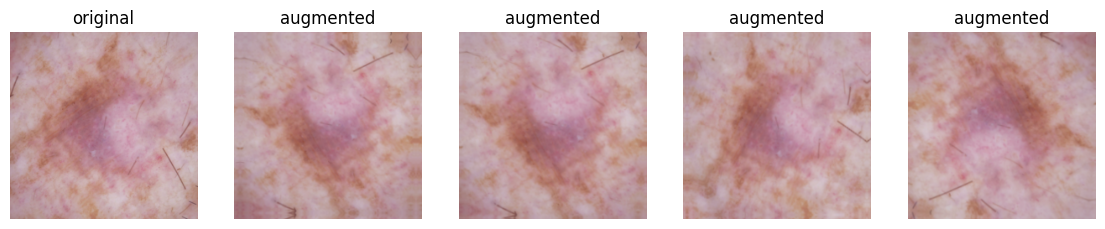

In [8]:
data_augmentation = keras.Sequential([
    # TODO Random layers here
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.25),
    layers.RandomZoom(0.1),
], name="data_augmentation")

# TODO Check: display the same image augmented 4 times (call data_augmentation with training=True)
img = X_train[:1].astype("float32")
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
axes[0].imshow(img[0].astype("uint8"))
axes[0].set_title("original")
for ax in axes[1:]:
    aug = data_augmentation(img, training=True)
    ax.imshow(np.clip(np.array(aug[0]), 0, 255).astype("uint8"))
    ax.set_title("augmented")
for ax in axes:
    ax.axis("off")
plt.show()

## 2. Baseline: a small CNN from scratch

Before using transfer learning, we need a reference point. Build a small CNN, similar to the one of the previous session, with one more convolution block because the images are larger:

| Layer | Settings |
|---|---|
| Input | shape `(IMAGE_SIZE, IMAGE_SIZE, 3)` |
| `data_augmentation` | |
| Rescaling | `1/255`, to scale pixels to [0, 1] |
| Conv2D + MaxPooling2D | 32 filters, 3 x 3, ReLU; 2 x 2 |
| Conv2D + MaxPooling2D | 64 filters, 3 x 3, ReLU; 2 x 2 |
| Conv2D + MaxPooling2D | 128 filters, 3 x 3, ReLU; 2 x 2 |
| Flatten + Dropout | 0.5 |
| Dense | 1 neuron, **sigmoid** |

With two classes, a single sigmoid output (the probability of *cancer*) with the `binary_crossentropy` loss is enough, and the labels stay as 0 / 1 (no one-hot encoding).

Compile it with `adam`, `binary_crossentropy` and `metrics=METRICS`.

In [9]:
def build_baseline():
    # TODO Define and compile the model
    model = keras.Sequential([
        layers.Input((IMAGE_SIZE, IMAGE_SIZE, 3)),
        data_augmentation,
        layers.Rescaling(1.0 / 255),
        layers.Conv2D(32, 3, activation="relu"),
        layers.MaxPooling2D(2),
        layers.Conv2D(64, 3, activation="relu"),
        layers.MaxPooling2D(2),
        layers.Conv2D(128, 3, activation="relu"),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dropout(0.5),
        layers.Dense(1, activation="sigmoid"),
    ], name="baseline_cnn")
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=METRICS)

    return model

baseline = build_baseline()
baseline.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │        86,529 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 179,777 (702.25 KB)

 Trainable params: 179,777 (702.25 KB)

 Non-trainable params: 0 (0.00 B)

Train it for at most 30 epochs with `batch_size=BATCH_SIZE`, the validation set, `class_weight=class_weight` and `callbacks=[early_stopping()]`. Early stopping monitors the validation ROC AUC here. Then plot the curves and evaluate the model on the validation set with `evaluate(baseline, X_valid, y_valid, "Baseline CNN")`.

Epoch 1/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 20s 57ms/step - accuracy: 0.5596 - auc: 0.6795 - loss: 0.6277 - recall: 0.7518 - val_accuracy: 0.5354 - val_auc: 0.6798 - val_loss: 0.7628 - val_recall: 0.9286
Epoch 2/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 11s 50ms/step - accuracy: 0.5720 - auc: 0.7199 - loss: 0.5803 - recall: 0.8734 - val_accuracy: 0.5204 - val_auc: 0.7171 - val_loss: 0.7801 - val_recall: 0.9745
Epoch 3/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 11s 50ms/step - accuracy: 0.5930 - auc: 0.7463 - loss: 0.5686 - recall: 0.8346 - val_accuracy: 0.5972 - val_auc: 0.7649 - val_loss: 0.5577 - val_recall: 0.9082
Epoch 4/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 11s 50ms/step - accuracy: 0.5814 - auc: 0.7412 - loss: 0.5769 - recall: 0.8309 - val_accuracy: 0.6640 - val_auc: 0.7658 - val_loss: 0.4951 - val_recall: 0.6939
Epoch 5/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 11s 50ms/step - accuracy: 0.6001 - auc: 0.7553 - loss: 0.5615 - recall: 0.8375 - val_accuracy: 0.6102 - val_auc: 0.7742 - val_loss: 0.5111 - val_recall: 0.7806


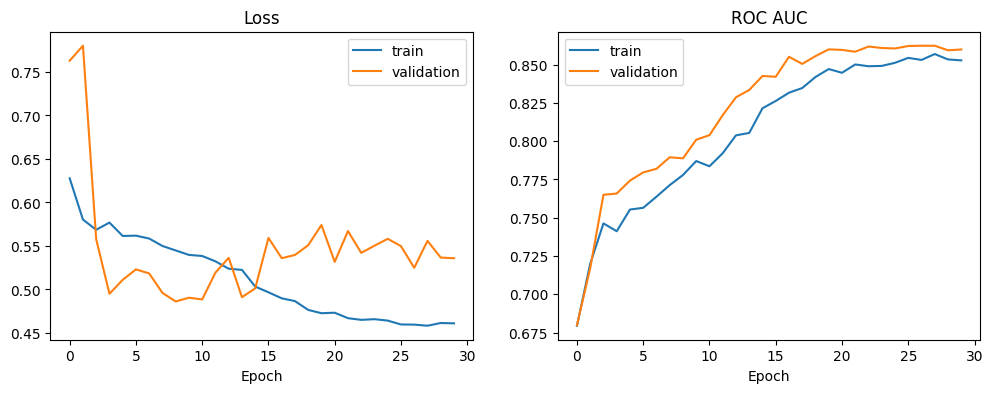

Baseline CNN
  balanced accuracy: 0.755
  recall (cancer): 0.867
  specificity: 0.642
  ROC AUC: 0.862


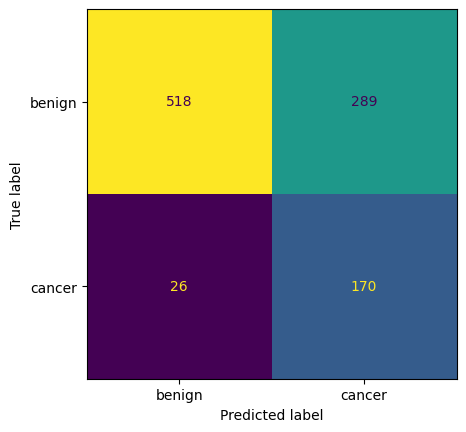

{'balanced accuracy': np.float64(0.7546152289912247),
 'recall (cancer)': 0.8673469387755102,
 'specificity': 0.6418835192069393,
 'ROC AUC': np.float64(0.8623144425056269)}

In [10]:
# TODO Train the baseline
hist_baseline = baseline.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    epochs=30, batch_size=BATCH_SIZE,
    class_weight=class_weight,
    callbacks=[early_stopping()],
)
# TODO Plot the curves and evaluate on the validation set
plot_history(hist_baseline)
evaluate(baseline, X_valid, y_valid, "Baseline CNN")

## 3. VGG16 as it is

VGG16 is a CNN with 13 convolution layers in 5 blocks, followed by 3 dense layers. It was trained to classify ImageNet photos into 1,000 everyday categories (animals, objects, food...).

Load it with its ImageNet weights and its classifier (`include_top=True`), and use it to predict the class of 3 validation images:
1. VGG16 expects 224 x 224 images, preprocessed with `keras.applications.vgg16.preprocess_input` (it converts RGB to BGR and subtracts the mean ImageNet pixel value);
2. display the top 3 predictions with `keras.applications.vgg16.decode_predictions`.

553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 32s 0us/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step


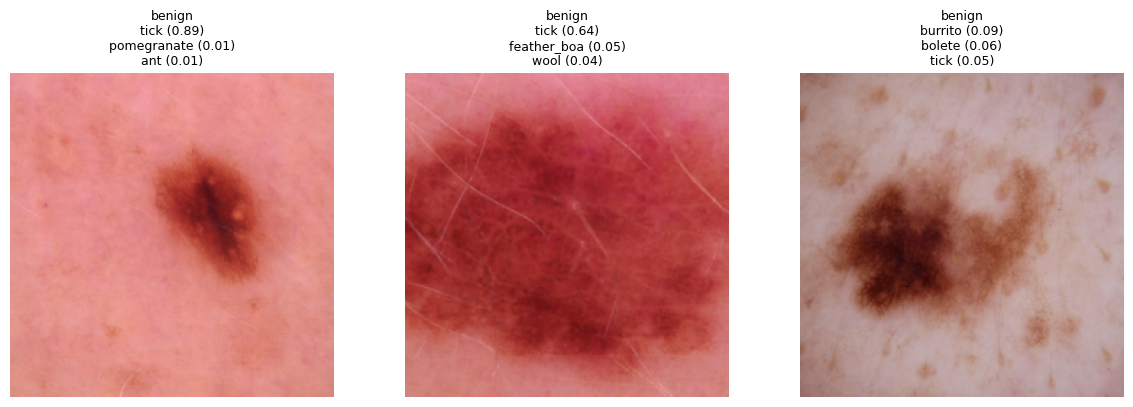

In [11]:
from keras.applications.vgg16 import preprocess_input, decode_predictions

# TODO Load VGG16 with its ImageNet classifier
vgg_full = keras.applications.VGG16(weights="imagenet", include_top=True)
# TODO Predict the top 3 ImageNet classes for 3 validation images
idx = [0, 1, 2]
imgs = tf.image.resize(X_valid[idx].astype("float32"), (224, 224)).numpy()
preds = vgg_full.predict(preprocess_input(imgs.copy()), verbose=0)
decoded = decode_predictions(preds, top=3)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, img, dec, i in zip(axes, imgs, decoded, idx):
    ax.imshow(img.astype("uint8"))
    ax.set_title(class_names[y_valid[i]] + "\n" + "\n".join(f"{n} ({p:.2f})" for _, n, p in dec), fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Question:** what do you observe? What does this tell us about what can, and cannot, be reused from VGG16?

*Your answer here:*

## 4. Transfer learning, step 1: feature extraction

We now build our model on top of the convolutional part of VGG16:
1. load VGG16 **without its classifier** (`include_top=False`) and with input shape `(IMAGE_SIZE, IMAGE_SIZE, 3)`. Without the dense layers, VGG16 accepts any image size of at least 32 x 32;
2. **freeze** it (`base.trainable = False`): its 14.7 million weights will not be modified. Only our new classifier is trained, so VGG16 acts as a fixed feature extractor;
3. add a new classifier (the **head**) on top: `Flatten`, `Dense(256, relu)`, `Dropout(0.5)`, `Dense(1, sigmoid)`.

The complete model is: input, `data_augmentation`, `preprocess_input`, VGG16, head. Calling `base(x, training=False)` keeps VGG16 in inference mode.

Write a function `build_vgg_model(conv_head=False)` with the Functional API. The `conv_head` argument will be used in the next section; ignore it for now. Then build the model and look at the summary: compare the total and trainable number of parameters.

In [12]:
def build_vgg_model(conv_head=False):
    # Load VGG16 without its classifier, and freeze it
    base = keras.applications.VGG16(
        weights="imagenet", include_top=False,
        input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    )
    base.trainable = False

    # Input, data augmentation, VGG16 preprocessing, VGG16
    inputs = keras.Input((IMAGE_SIZE, IMAGE_SIZE, 3))
    x = data_augmentation(inputs)
    x = preprocess_input(x)
    x = base(x, training=False)

    if conv_head:
        x = layers.Conv2D(64, 3, activation="relu")(x)

    # New classifier
    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    # Build and compile the model
    model = keras.Model(inputs, outputs, name="vgg_conv_head" if conv_head else "vgg_flat_head")
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=METRICS)
    return model

vgg_flat = build_vgg_model()
vgg_flat.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "vgg_flat_head"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 224, 224,  │          0 │ input_layer_4[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ data_augmentatio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 25088)     │          0 │ vgg16[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 256)       │  6,422,784 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │        257 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 21,137,729 (80.63 MB)

 Trainable params: 6,423,041 (24.50 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Train it like the baseline (at most 30 epochs, class weights, early stopping), plot the curves and evaluate it on the validation set under the name `"VGG16 + Flatten head"`.

Epoch 1/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 51s 218ms/step - accuracy: 0.6558 - auc: 0.7518 - loss: 1.9760 - recall: 0.7919 - val_accuracy: 0.7049 - val_auc: 0.8525 - val_loss: 0.4857 - val_recall: 0.8571
Epoch 2/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 42s 190ms/step - accuracy: 0.6748 - auc: 0.8281 - loss: 0.5498 - recall: 0.8397 - val_accuracy: 0.7577 - val_auc: 0.8674 - val_loss: 0.4425 - val_recall: 0.8214
Epoch 3/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 44s 199ms/step - accuracy: 0.7538 - auc: 0.8390 - loss: 0.5208 - recall: 0.7540 - val_accuracy: 0.7966 - val_auc: 0.8660 - val_loss: 0.4035 - val_recall: 0.7296
Epoch 4/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 43s 195ms/step - accuracy: 0.7672 - auc: 0.8569 - loss: 0.4715 - recall: 0.7679 - val_accuracy: 0.7886 - val_auc: 0.8656 - val_loss: 0.5096 - val_recall: 0.8010
Epoch 5/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 43s 198ms/step - accuracy: 0.7826 - auc: 0.8555 - loss: 0.4939 - recall: 0.7621 - val_accuracy: 0.7707 - val_auc: 0.8855 - val_loss: 0.4936 - val_recall: 0.

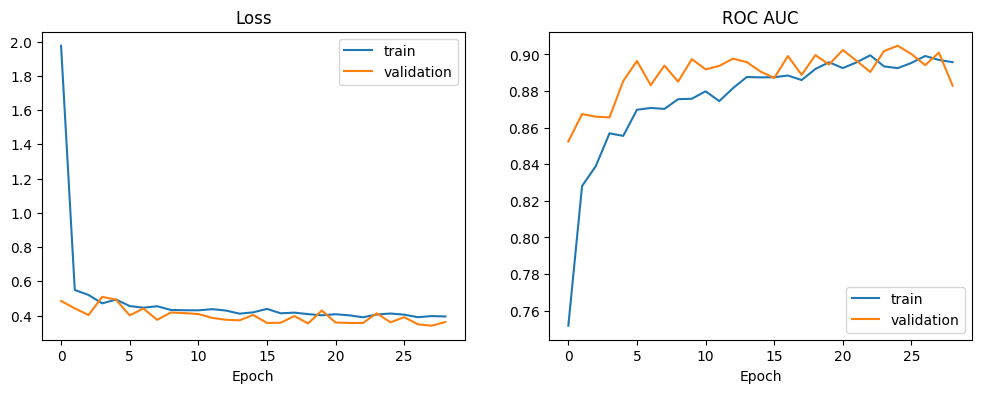

VGG16 + Flatten head
  balanced accuracy: 0.804
  recall (cancer): 0.750
  specificity: 0.859
  ROC AUC: 0.904


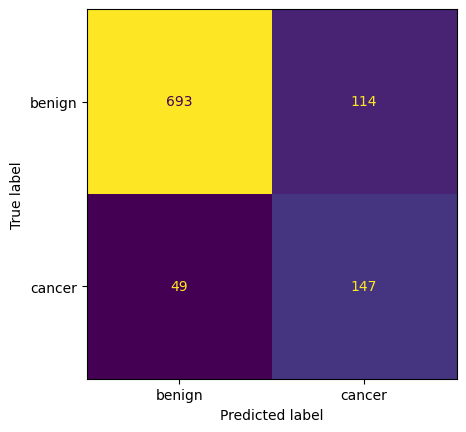

{'balanced accuracy': np.float64(0.804368029739777),
 'recall (cancer)': 0.75,
 'specificity': 0.8587360594795539,
 'ROC AUC': np.float64(0.9044805654603848)}

In [13]:
# TODO Train, plot the curves, evaluate on the validation set
hist_flat = vgg_flat.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    epochs=30, batch_size=BATCH_SIZE,
    class_weight=class_weight,
    callbacks=[early_stopping()],
)

plot_history(hist_flat)
evaluate(vgg_flat, X_valid, y_valid, "VGG16 + Flatten head")

**Question:** compare with the baseline. What do you observe on the learning curves?

*Your observations here:*

## 5. A paradox: adding a layer can reduce the number of parameters

Look again at the summary of `vgg_flat`. Almost all the trainable parameters are in a single layer: the first `Dense` layer of the head.

Now suppose we insert one more layer, a `Conv2D` with 64 filters of size 3 x 3 (ReLU, no padding), between VGG16 and `Flatten`.

**Question:** before running any code, predict: will the total number of parameters of the model increase or decrease? Write down your prediction and your reasoning.

*Your prediction:* the total number of parameters should **decrease**. Reasoning: a `Dense` layer has (inputs x units + units) parameters, so the first Dense of the head is huge because `Flatten` produces a very long vector (7 x 7 x 512 = 25,088 values at 224 x 224). A `Conv2D` with 64 filters of size 3 x 3 has few parameters of its own and, without padding, it reduces the spatial size (7 x 7 -> 5 x 5) and the depth (512 -> 64 channels), so `Flatten` produces a much shorter vector (5 x 5 x 64 = 1,600) and the following Dense layer shrinks a lot.

Now check: build the model with `build_vgg_model(conv_head=True)` (complete your function if needed) and compare the total and trainable number of parameters of both models with `count_params()`. The trainable parameters are the sum of the sizes of `model.trainable_weights`.

In [14]:
# TODO Build the model with the convolution layer and compare the numbers of parameters
vgg_conv = build_vgg_model(conv_head=True)

def n_trainable(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))

for name, m in [("Flatten head", vgg_flat), ("Conv head", vgg_conv)]:
    print(f"{name}: total = {m.count_params():,} | trainable = {n_trainable(m):,}")

Flatten head: total = 21,137,729 | trainable = 6,423,041
Conv head: total = 15,419,777 | trainable = 705,089


**Question:** explain the result. Why does adding a layer reduce the number of parameters?

*Hint:* for each layer of the head, compute by hand the shape of its output and its number of parameters. What does the number of parameters of a `Dense` layer depend on? And that of a `Conv2D` layer?

*Your answer here:*

Train `vgg_conv` in the same way and evaluate it on the validation set under the name `"VGG16 + Conv head"`. Does the smaller head change the results?

Epoch 1/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 46s 201ms/step - accuracy: 0.6966 - auc: 0.7915 - loss: 0.7070 - recall: 0.7542 - val_accuracy: 0.6361 - val_auc: 0.8390 - val_loss: 0.5904 - val_recall: 0.9592
Epoch 2/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 42s 193ms/step - accuracy: 0.7213 - auc: 0.8542 - loss: 0.4688 - recall: 0.8580 - val_accuracy: 0.7338 - val_auc: 0.8615 - val_loss: 0.4434 - val_recall: 0.7857
Epoch 3/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 42s 193ms/step - accuracy: 0.7297 - auc: 0.8687 - loss: 0.4489 - recall: 0.8631 - val_accuracy: 0.7338 - val_auc: 0.8717 - val_loss: 0.4597 - val_recall: 0.8776
Epoch 4/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 43s 197ms/step - accuracy: 0.7323 - auc: 0.8719 - loss: 0.4425 - recall: 0.8558 - val_accuracy: 0.7707 - val_auc: 0.8848 - val_loss: 0.4224 - val_recall: 0.8316
Epoch 5/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 43s 195ms/step - accuracy: 0.7617 - auc: 0.8853 - loss: 0.4249 - recall: 0.8631 - val_accuracy: 0.7717 - val_auc: 0.8891 - val_loss: 0.4263 - val_recall: 0.

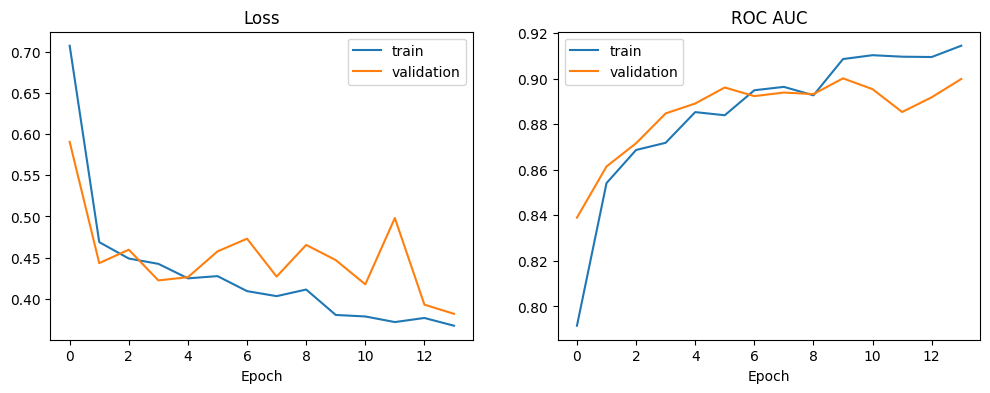

VGG16 + Conv head
  balanced accuracy: 0.804
  recall (cancer): 0.878
  specificity: 0.730
  ROC AUC: 0.900


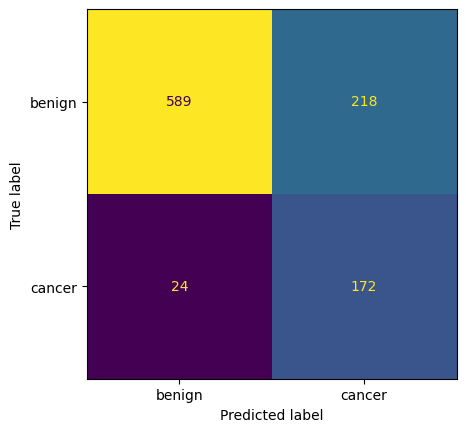

{'balanced accuracy': np.float64(0.8037073565485674),
 'recall (cancer)': 0.8775510204081632,
 'specificity': 0.7298636926889716,
 'ROC AUC': np.float64(0.9001782869281542)}

In [15]:
# TODO Train, plot the curves, evaluate on the validation set
hist_conv = vgg_conv.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    epochs=30, batch_size=BATCH_SIZE,
    class_weight=class_weight,
    callbacks=[early_stopping()],
)

plot_history(hist_conv)
evaluate(vgg_conv, X_valid, y_valid, "VGG16 + Conv head")

## 6. Transfer learning, step 2: fine-tuning

So far, VGG16 was frozen: its features were learned on ImageNet photos, not on skin lesions. **Fine-tuning** adapts some of them to our data by unfreezing the last layers of VGG16 and training them together with the head.

We only unfreeze the last block (`block5`): the first blocks detect generic features (edges, colors, textures) that are useful as they are, while the last block detects more specific shapes, which benefit most from adaptation.

Two important rules:
- fine-tune a model whose head is **already trained** (the model from step 1). A random head would send large, random gradients into VGG16 and destroy its pretrained features;
- use a **very small learning rate** (here `1e-5`, 100 times smaller than Adam's default), to adjust the pretrained weights slightly rather than overwrite them.

Steps:
1. make a **copy** of the model from step 1 with the best validation ROC AUC: build a new model with `build_vgg_model` (same head) and copy the trained weights with `set_weights(... .get_weights())`. This keeps the step-1 model unchanged for the final comparison;
2. get its VGG16 part with `model.get_layer("vgg16")`, set `base.trainable = True`, then set `layer.trainable = False` for every layer whose name does not start with `"block5"`;
3. **recompile** the model (required for the change to take effect) with `keras.optimizers.Adam(learning_rate=1e-5)`;
4. check the new number of trainable parameters, then train for at most 15 epochs and evaluate under the name `"VGG16 fine-tuned"`.

In [16]:
# TODO

# 1. Copy of the model from step 1 with the best validation ROC AUC
#    (early stopping already restored the best weights of vgg_flat)
vgg_ft = build_vgg_model()
vgg_ft.set_weights(vgg_flat.get_weights())

# 2. Unfreeze block5 of VGG16
base = vgg_ft.get_layer("vgg16")
base.trainable = True
for layer in base.layers:
    layer.trainable = layer.name.startswith("block5")

# 3. Recompile with a small learning rate
vgg_ft.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy", metrics=METRICS,
)

# 4. Number of trainable parameters
print(f"Trainable parameters: {n_trainable(vgg_ft):,} (before: {n_trainable(vgg_flat):,})")

Trainable parameters: 13,502,465 (before: 6,423,041)


Epoch 1/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 54s 232ms/step - accuracy: 0.8345 - auc: 0.9064 - loss: 0.3799 - recall: 0.7785 - val_accuracy: 0.8315 - val_auc: 0.9082 - val_loss: 0.3745 - val_recall: 0.7908
Epoch 2/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 48s 221ms/step - accuracy: 0.8373 - auc: 0.9108 - loss: 0.3653 - recall: 0.7760 - val_accuracy: 0.8375 - val_auc: 0.9114 - val_loss: 0.3686 - val_recall: 0.7959
Epoch 3/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 49s 224ms/step - accuracy: 0.8442 - auc: 0.9147 - loss: 0.3617 - recall: 0.7862 - val_accuracy: 0.8315 - val_auc: 0.9182 - val_loss: 0.3608 - val_recall: 0.8112
Epoch 4/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 49s 222ms/step - accuracy: 0.8440 - auc: 0.9184 - loss: 0.3507 - recall: 0.7811 - val_accuracy: 0.8684 - val_auc: 0.9110 - val_loss: 0.3165 - val_recall: 0.7041
Epoch 5/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 48s 221ms/step - accuracy: 0.8453 - auc: 0.9252 - loss: 0.3358 - recall: 0.8053 - val_accuracy: 0.8295 - val_auc: 0.9207 - val_loss: 0.3775 - val_recall: 0.

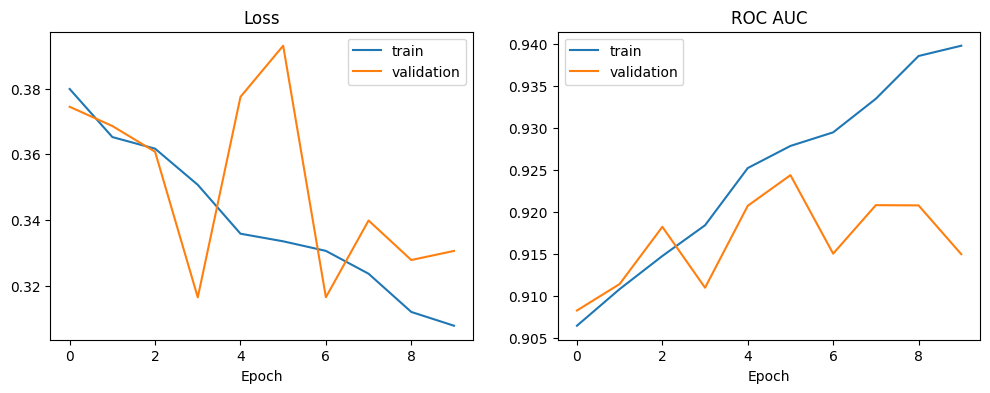

VGG16 fine-tuned
  balanced accuracy: 0.830
  recall (cancer): 0.847
  specificity: 0.813
  ROC AUC: 0.924


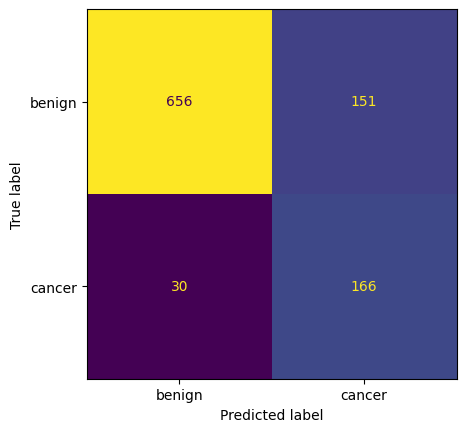

{'balanced accuracy': np.float64(0.8299130060946311),
 'recall (cancer)': 0.8469387755102041,
 'specificity': 0.8128872366790583,
 'ROC AUC': np.float64(0.9243102445439142)}

In [17]:
# TODO Train, plot the curves, evaluate on the validation set
hist_ft = vgg_ft.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    epochs=15, batch_size=BATCH_SIZE,
    class_weight=class_weight,
    callbacks=[early_stopping()],
)

plot_history(hist_ft)
evaluate(vgg_ft, X_valid, y_valid, "VGG16 fine-tuned")

## 7. Final evaluation on the test set

Compare all the models on the validation set, choose the best one according to the validation ROC AUC, and evaluate it **once** on the test set.

*In the previous sessions, we retrained the chosen model on train + validation before testing. Here, retraining VGG16 in two stages would take a lot of GPU time, so we evaluate the selected model directly. Both approaches are valid; what matters is that the test set is used only once, for the final model.*

,balanced accuracy,recall (cancer),specificity,ROC AUC
VGG16 fine-tuned,0.829913,0.846939,0.812887,0.924310
VGG16 + Flatten head,0.804368,0.750000,0.858736,0.904481
VGG16 + Conv head,0.803707,0.877551,0.729864,0.900178
Baseline CNN,0.754615,0.867347,0.641884,0.862314


Best model on validation: VGG16 fine-tuned
TEST - VGG16 fine-tuned
  balanced accuracy: 0.837
  recall (cancer): 0.849
  specificity: 0.825
  ROC AUC: 0.921


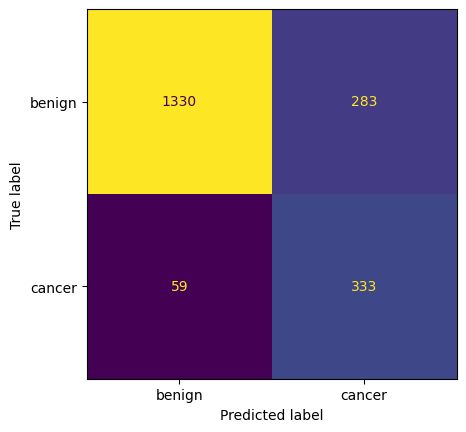

In [18]:
# TODO Compare the models on the validation set (pd.DataFrame(results).T)
val_table = pd.DataFrame(results).T
display(val_table.sort_values("ROC AUC", ascending=False))

# TODO Select the best one by validation ROC AUC and evaluate it on the test set
models = {
    "Baseline CNN": baseline,
    "VGG16 + Flatten head": vgg_flat,
    "VGG16 + Conv head": vgg_conv,
    "VGG16 fine-tuned": vgg_ft,
}
best_name = val_table["ROC AUC"].idxmax()
print("Best model on validation:", best_name)
test_scores = evaluate(models[best_name], X_test, y_test, f"TEST - {best_name}")

**Question:** comment on the test results. Would you use this model in a clinic?

*Your answer here:*

## Going further

Compare versions **on the validation set**:
- **Threshold:** the 0.5 threshold is arbitrary. Plot recall and specificity on the validation set for thresholds from 0.1 to 0.9, and choose one that gives a recall of at least 90%.
- **Head:** replace `Flatten` by `GlobalAveragePooling2D` in `build_vgg_model`. How many trainable parameters are left? How do the results change?
- **Fine-tuning:** also unfreeze `block4`. Does it help, or does it overfit?
- **Other pretrained models:** try `keras.applications.ResNet50` or `EfficientNetB0`, each with its own `preprocess_input`.
- **7 classes:** go back to the original 7-class problem (softmax output with 7 neurons, `sparse_categorical_crossentropy` loss).